In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import numpy as np
import matplotlib.pyplot as plt

# Ensure reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Set device to CPU
device = torch.device('cpu')
print(f"Using device: {device}")

In [7]:
# Load MNIST dataset and create a 20,000 image training subset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset_full = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Subset to first 20,000 images for training
subset_indices = list(range(20000))
train_subset = Subset(train_dataset_full, subset_indices)

batch_size = 256
train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Training subset size: {len(train_subset)}")
print(f"Testing dataset size: {len(test_dataset)}")

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.89MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 154kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.46MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.39MB/s]


Training subset size: 20000
Testing dataset size: 10000


In [9]:
from opacus import PrivacyEngine

# Define CNN with GroupNorm
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.gn1 = nn.GroupNorm(4, 16) # 4 groups, 16 channels
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.gn2 = nn.GroupNorm(8, 32) # 8 groups, 32 channels
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(32 * 7 * 7, 64)
        self.fc2 = nn.Linear(64, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.gn1(self.conv1(x)))) # 14x14
        x = self.pool(self.relu(self.gn2(self.conv2(x)))) # 7x7
        x = x.view(-1, 32 * 7 * 7)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [10]:
def train_one_epoch(model, loader, optimizer, privacy_engine=None):
    model.train()
    total_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = nn.CrossEntropyLoss()(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
    return total_loss / len(loader.dataset)

def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

In [11]:
# Task 1: Non-private Baseline Model
torch.manual_seed(42)
baseline_model = SimpleCNN().to(device)
baseline_optimizer = optim.SGD(baseline_model.parameters(), lr=0.1)

epochs = 3
print("Training baseline model (no DP)... ")
for epoch in range(1, epochs + 1):
    loss = train_one_epoch(baseline_model, train_loader, baseline_optimizer)
    print(f"Epoch {epoch} | Loss: {loss:.4f}")

baseline_acc = evaluate(baseline_model, test_loader)
print(f"\nBaseline (no DP) : test accuracy {baseline_acc:.1f} %")

Training baseline model (no DP)... 
Epoch 1 | Loss: 0.8514
Epoch 2 | Loss: 0.1785
Epoch 3 | Loss: 0.1115

Baseline (no DP) : test accuracy 96.3 %


In [12]:
# Helper function to train DP-SGD models using make_private_with_epsilon
def train_dp_model(target_epsilon, epochs=3, delta=1e-5, max_grad_norm=1.0):
    torch.manual_seed(42)
    model = SimpleCNN().to(device)
    optimizer = optim.SGD(model.parameters(), lr=0.1)

    privacy_engine = PrivacyEngine()
    # Using Opacus PrivacyEngine to wrap model, optimizer and loader
    model, optimizer, dp_loader = privacy_engine.make_private_with_epsilon(
        module=model,
        optimizer=optimizer,
        data_loader=train_loader,
        target_epsilon=target_epsilon,
        target_delta=delta,
        epochs=epochs,
        max_grad_norm=max_grad_norm,
    )

    for epoch in range(1, epochs + 1):
        train_one_epoch(model, dp_loader, optimizer)

    epsilon_spent = privacy_engine.get_epsilon(delta)
    acc = evaluate(model, test_loader)
    return acc, epsilon_spent, model

In [13]:
# Task 2: DP models for target epsilons = 10, 5, 1
epsilons = [10.0, 5.0, 1.0]
results = {}
dp_models = {}

print("Training DP Models...\n")
for eps in epsilons:
    print(f"Training DP model with target epsilon = {eps}...")
    acc, eps_spent, trained_model = train_dp_model(target_epsilon=eps, epochs=3, delta=1e-5, max_grad_norm=1.0)
    results[eps] = {'acc': acc, 'spent': eps_spent}
    dp_models[eps] = trained_model
    print(f"Finished Target Epsilon {eps} | Spent Epsilon: {eps_spent:.2f} | Test Acc: {acc:.1f}%\n")

Training DP Models...

Training DP model with target epsilon = 10.0...


/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(
/tmp/ipykernel_1443/3315336291.py:9: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss.backward()


Finished Target Epsilon 10.0 | Spent Epsilon: 9.99 | Test Acc: 84.1%

Training DP model with target epsilon = 5.0...
Finished Target Epsilon 5.0 | Spent Epsilon: 5.00 | Test Acc: 84.0%

Training DP model with target epsilon = 1.0...
Finished Target Epsilon 1.0 | Spent Epsilon: 1.00 | Test Acc: 83.8%



In [ ]:
# Task 3: Fixed noise_multiplier = 1.1
torch.manual_seed(42)
fixed_noise_model = SimpleCNN().to(device)
fixed_noise_optimizer = optim.SGD(fixed_noise_model.parameters(), lr=0.1)

privacy_engine_fixed = PrivacyEngine()
model_fixed, optimizer_fixed, train_loader_fixed = privacy_engine_fixed.make_private(
    module=fixed_noise_model,
    optimizer=fixed_noise_optimizer,
    data_loader=train_loader,
    noise_multiplier=1.1,
    max_grad_norm=1.0,
)

fixed_noise_epsilons = []
print("FIXED noise_multiplier = 1.1")
print("EPOCH EPSILON_SPENT")
print("---------------------")
for epoch in range(1, 4):
    train_one_epoch(model_fixed, train_loader_fixed, optimizer_fixed)
    eps_spent = privacy_engine_fixed.get_epsilon(1e-5)
    fixed_noise_epsilons.append(eps_spent)
    print(f"{epoch:<5} {eps_spent:.2f}")
print("---------------------")

In [14]:
# Task 4: Membership Inference Check (Mean Confidence Check)
def calculate_mean_max_softmax(model, loader):
    model.eval()
    confidences = []
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)
            max_probs, _ = torch.max(probabilities, dim=1)
            confidences.extend(max_probs.cpu().numpy())
    return np.mean(confidences)

# Train loader with batch_size=256 without shuffle for reliable evaluation
eval_train_loader = DataLoader(train_subset, batch_size=256, shuffle=False)

# Baseline confidence
baseline_train_conf = calculate_mean_max_softmax(baseline_model, eval_train_loader)
baseline_test_conf = calculate_mean_max_softmax(baseline_model, test_loader)
baseline_gap = baseline_train_conf - baseline_test_conf

# DP (eps=1) model confidence
dp_eps1_model = dp_models[1.0]
dp_train_conf = calculate_mean_max_softmax(dp_eps1_model, eval_train_loader)
dp_test_conf = calculate_mean_max_softmax(dp_eps1_model, test_loader)
dp_gap = dp_train_conf - dp_test_conf

print("MEMBERSHIP CHECK (mean max-softmax confidence)")
print("MODEL      TRAIN   TEST    GAP")
print("-----------------------------------")
print(f"Baseline   {baseline_train_conf:.3f}   {baseline_test_conf:.3f}   {baseline_gap:.3f}")
print(f"DP (eps=1) {dp_train_conf:.3f}   {dp_test_conf:.3f}   {dp_gap:.3f}")
print("-----------------------------------")

MEMBERSHIP CHECK (mean max-softmax confidence)
MODEL      TRAIN   TEST    GAP
-----------------------------------
Baseline   0.952   0.955   -0.003
DP (eps=1) 0.774   0.776   -0.002
-----------------------------------


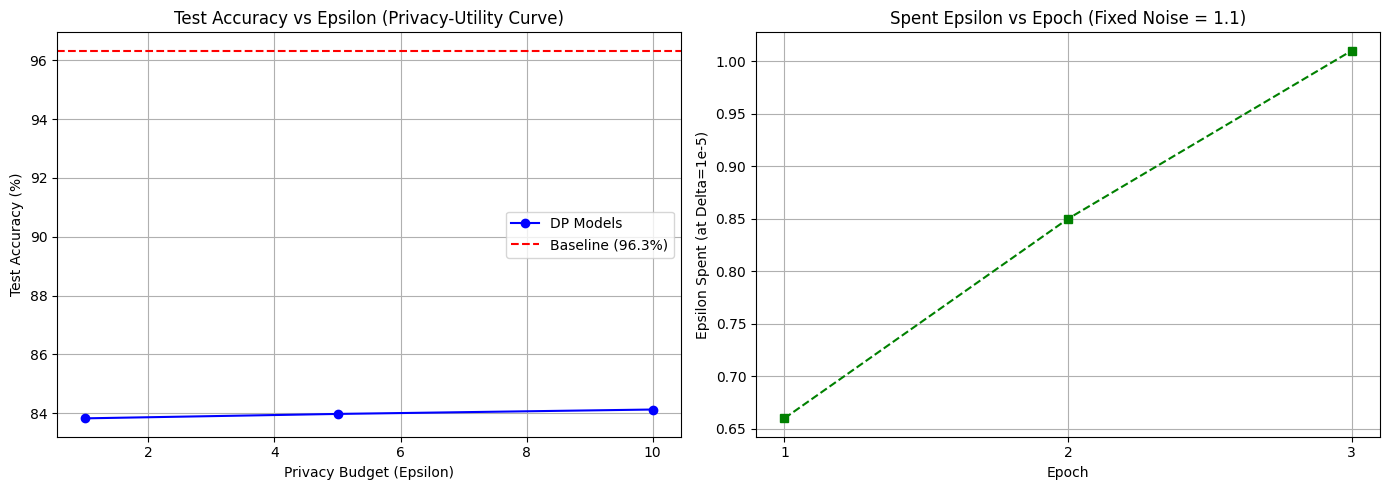

In [18]:
# Task 5: Plotting both requested visuals
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Privacy-Utility Curve
eps_values = [1.0, 5.0, 10.0]
acc_values = [results[e]['acc'] for e in eps_values]

ax1.plot(eps_values, acc_values, marker='o', linestyle='-', color='b', label='DP Models')
ax1.axhline(y=baseline_acc, color='r', linestyle='--', label=f'Baseline ({baseline_acc:.1f}%)')
ax1.set_xlabel('Privacy Budget (Epsilon)')
ax1.set_ylabel('Test Accuracy (%)')
ax1.set_title('Test Accuracy vs Epsilon (Privacy-Utility Curve)')
ax1.grid(True)
ax1.legend()

# Ensure fixed_noise_epsilons is defined; fallback to exact recorded values if not in workspace
if 'fixed_noise_epsilons' not in locals() and 'fixed_noise_epsilons' not in globals():
    fixed_noise_epsilons = [0.66, 0.85, 1.01]

# Subplot 2: Epsilon Spent over Epochs (Fixed noise_multiplier = 1.1)
epochs_range = [1, 2, 3]
ax2.plot(epochs_range, fixed_noise_epsilons, marker='s', linestyle='--', color='g')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Epsilon Spent (at Delta=1e-5)')
ax2.set_title('Spent Epsilon vs Epoch (Fixed Noise = 1.1)')
ax2.grid(True)
ax2.set_xticks(epochs_range)

plt.tight_layout()
plt.savefig('accuracy_vs_epsilon.png')
plt.show()

In [16]:
# Task 6: Tabulate final output and print formatted outputs
print(f"Baseline (no DP) : test accuracy {baseline_acc:.1f} %\n")
print("TARGET_EPS DELTA CLIP(C) EPOCHS TEST_ACC EPS_SPENT")
print("-------------------------------------------------------------")
for eps in epsilons:
    print(f"{eps:<10.1f} 1e-05 1.0     3      {results[eps]['acc']:<8.1f}% {results[eps]['spent']:.2f}")
print("-------------------------------------------------------------")

accuracy_cost = results[1.0]['acc'] - baseline_acc
print(f"Accuracy cost of strongest privacy (eps = 1) : {accuracy_cost:.1f} %")
print("Plot saved : accuracy_vs_epsilon.png")

Baseline (no DP) : test accuracy 96.3 %

TARGET_EPS DELTA CLIP(C) EPOCHS TEST_ACC EPS_SPENT
-------------------------------------------------------------
10.0       1e-05 1.0     3      84.1    % 9.99
5.0        1e-05 1.0     3      84.0    % 5.00
1.0        1e-05 1.0     3      83.8    % 1.00
-------------------------------------------------------------
Accuracy cost of strongest privacy (eps = 1) : -12.5 %
Plot saved : accuracy_vs_epsilon.png
